# Day 40: DAS Reconstruction Using Cubic Spline Interpolation

## Objective
Evaluate the effect of cubic spline interpolation on DAS image
reconstruction when sensor data are missing.

## Methods
- Full-array DAS reference
- DAS with inactive sensors
- DAS after linear interpolation
- DAS after cubic spline interpolation

Full signal matrix shape: (32, 600)
Number of inactive sensors: 8
Inactive sensor indices: [1, 5, 9, 13, 17, 21, 25, 29]
Linear signal matrix shape: (32, 600)
Spline signal matrix shape: (32, 600)
DAS reconstruction completed.
Image shape: (100, 100)

Image errors relative to full-array DAS reference:
Incomplete data: {'MAE': 1.87869445319226, 'RMSE': 2.672719028774945, 'Max absolute error': 7.991632098505814}
Linear interpolation: {'MAE': 0.02309349721662082, 'RMSE': 0.03424056163235236, 'Max absolute error': 0.13848989583368265}
Cubic spline interpolation: {'MAE': 0.003930298799607742, 'RMSE': 0.006160354733979466, 'Max absolute error': 0.019551118761615527}

RMSE reduction compared with incomplete DAS:
Linear (%): 98.71888659961213
Spline (%): 99.76950982622355
Spline RMSE reduction compared with linear (%): 82.00860488176448


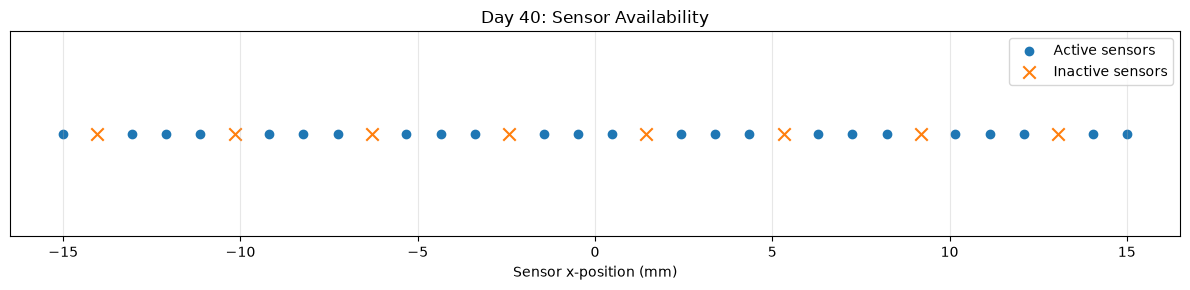

C:\Users\user\AppData\Local\Temp\ipykernel_3620\3013364273.py:282: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


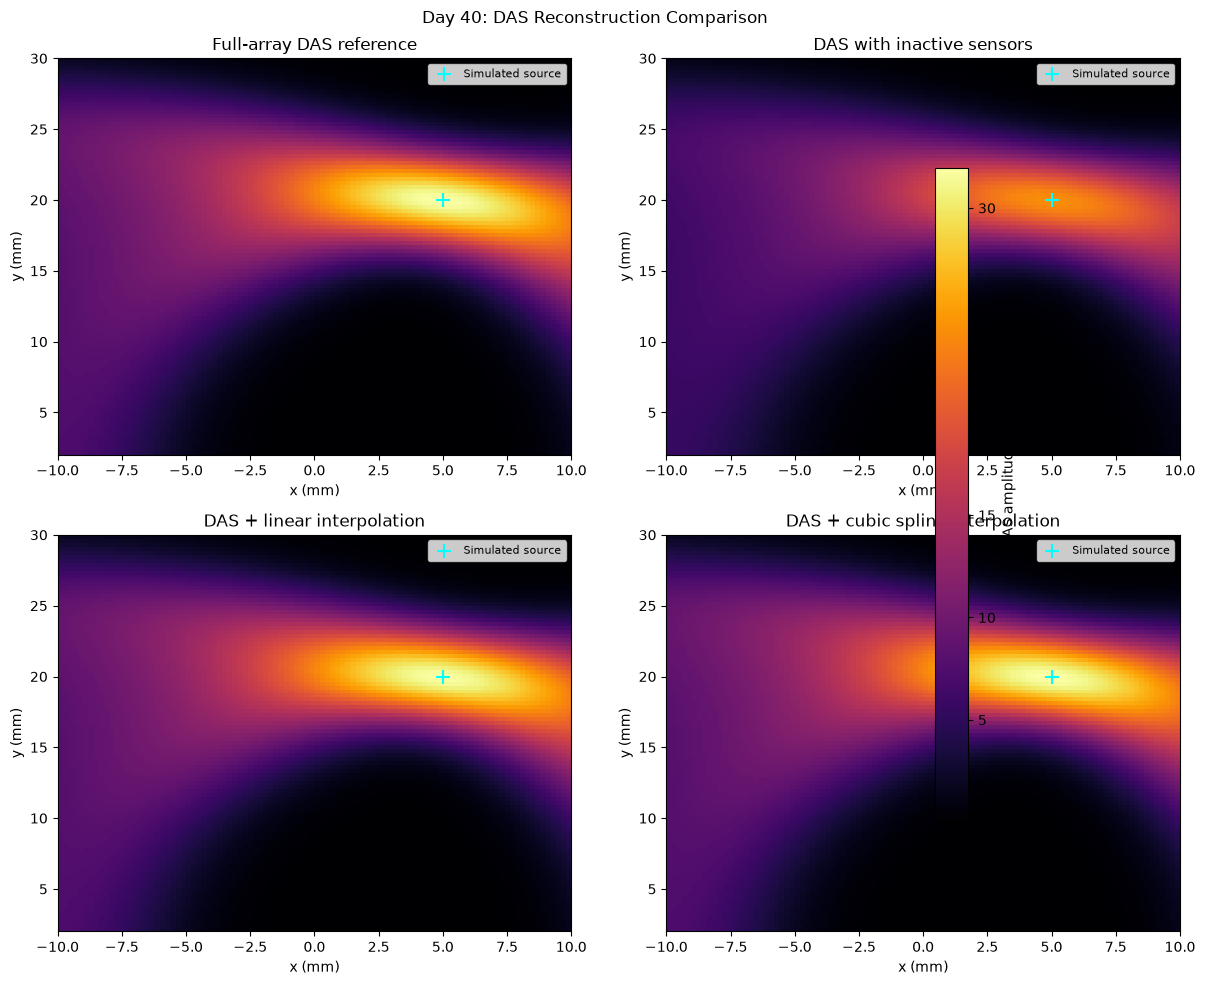

C:\Users\user\AppData\Local\Temp\ipykernel_3620\3013364273.py:333: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


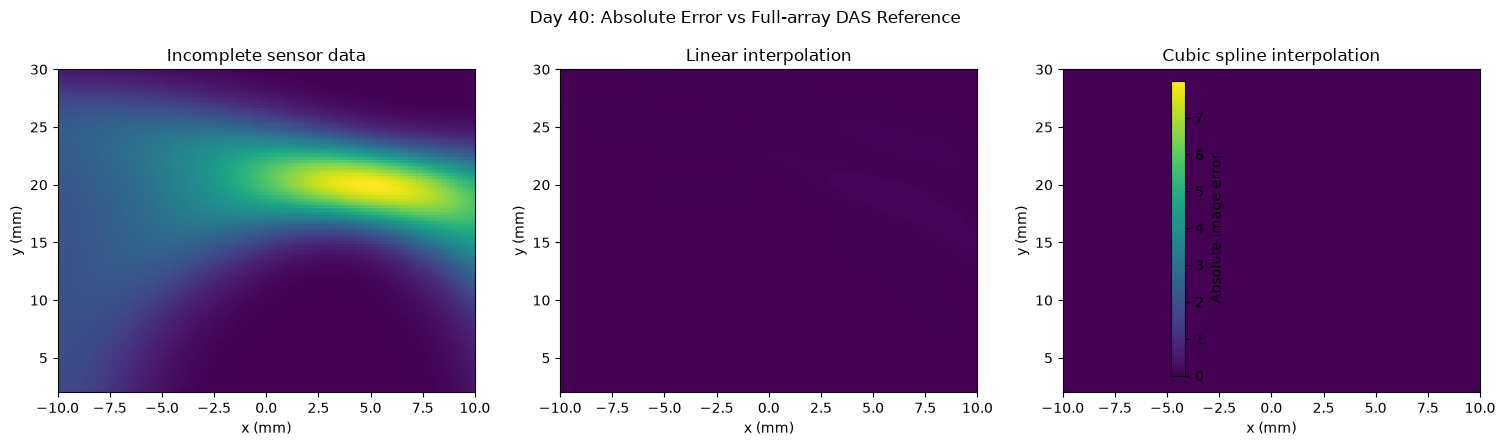

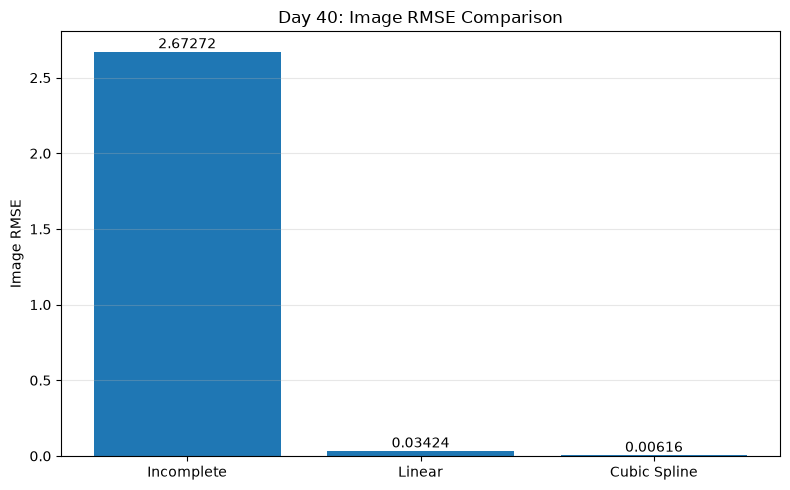


Results saved to: ..\outputs\day40_das_spline_results.json
{
    "day": 40,
    "method": "DAS with cubic spline interpolation",
    "num_sensors": 32,
    "num_inactive_sensors": 8,
    "dropout_fraction": 0.25,
    "inactive_sensor_indices_zero_based": [
        1,
        5,
        9,
        13,
        17,
        21,
        25,
        29
    ],
    "reference": "Full-array DAS image; synthetic computational reference, not physical ground truth",
    "image_errors": {
        "incomplete": {
            "MAE": 1.87869445319226,
            "RMSE": 2.672719028774945,
            "Max absolute error": 7.991632098505814
        },
        "linear_interpolation": {
            "MAE": 0.02309349721662082,
            "RMSE": 0.03424056163235236,
            "Max absolute error": 0.13848989583368265
        },
        "cubic_spline_interpolation": {
            "MAE": 0.003930298799607742,
            "RMSE": 0.006160354733979466,
            "Max absolute error": 0.0195511187616155

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d, CubicSpline

# --------------------------------------------------
# 1. Configuration
# --------------------------------------------------
num_sensors = 32
num_samples = 600
fs = 10e6
c = 1500.0  # Speed of sound (m/s)

source_x = 5e-3
source_y = 20e-3
pulse_width = 1.5e-6

sensor_x = np.linspace(-15e-3, 15e-3, num_sensors)
sensor_y = np.zeros(num_sensors)
time = np.arange(num_samples) / fs

x_grid = np.linspace(-10e-3, 10e-3, 100)
y_grid = np.linspace(2e-3, 30e-3, 100)
X, Y = np.meshgrid(x_grid, y_grid)

output_dir = Path("../outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# --------------------------------------------------
# 2. Generate synthetic sensor signals
# --------------------------------------------------
signals_full = np.zeros((num_sensors, num_samples))

for i in range(num_sensors):
    distance = np.sqrt(
        (sensor_x[i] - source_x) ** 2
        + (sensor_y[i] - source_y) ** 2
    )

    arrival_time = distance / c

    signals_full[i] = np.exp(
        -0.5 * ((time - arrival_time) / pulse_width) ** 2
    )

print("Full signal matrix shape:", signals_full.shape)

# --------------------------------------------------
# 3. Simulate inactive sensors (25% dropout)
# --------------------------------------------------
missing_indices = np.array([1, 5, 9, 13, 17, 21, 25, 29])

sensor_mask = np.ones(num_sensors, dtype=bool)
sensor_mask[missing_indices] = False

signals_missing = signals_full.copy()
signals_missing[~sensor_mask, :] = 0.0

print("Number of inactive sensors:", len(missing_indices))
print("Inactive sensor indices:", missing_indices.tolist())

# --------------------------------------------------
# 4. Linear interpolation
# --------------------------------------------------
known_x = sensor_x[sensor_mask]
known_signals = signals_full[sensor_mask, :]

linear_interpolator = interp1d(
    known_x,
    known_signals,
    axis=0,
    kind="linear",
    bounds_error=False,
    fill_value="extrapolate"
)

signals_linear = signals_missing.copy()
signals_linear[~sensor_mask, :] = linear_interpolator(
    sensor_x[~sensor_mask]
)

# --------------------------------------------------
# 5. Cubic spline interpolation
# --------------------------------------------------
spline_interpolator = CubicSpline(
    known_x,
    known_signals,
    axis=0,
    bc_type="natural",
    extrapolate=True
)

signals_spline = signals_missing.copy()
signals_spline[~sensor_mask, :] = spline_interpolator(
    sensor_x[~sensor_mask]
)

print("Linear signal matrix shape:", signals_linear.shape)
print("Spline signal matrix shape:", signals_spline.shape)

# --------------------------------------------------
# 6. Delay-and-Sum reconstruction
# --------------------------------------------------
def das_reconstruction(signals):
    image = np.zeros_like(X, dtype=float)

    for i in range(num_sensors):
        distance_map = np.sqrt(
            (X - sensor_x[i]) ** 2
            + (Y - sensor_y[i]) ** 2
        )

        travel_time_map = distance_map / c

        delayed_values = np.interp(
            travel_time_map.ravel(),
            time,
            signals[i],
            left=0.0,
            right=0.0
        ).reshape(X.shape)

        image += delayed_values

    return image


image_full = das_reconstruction(signals_full)
image_missing = das_reconstruction(signals_missing)
image_linear = das_reconstruction(signals_linear)
image_spline = das_reconstruction(signals_spline)

print("DAS reconstruction completed.")
print("Image shape:", image_full.shape)

# --------------------------------------------------
# 7. Image error metrics
# --------------------------------------------------
def calculate_errors(reference, estimate):
    difference = estimate - reference

    return {
        "MAE": float(np.mean(np.abs(difference))),
        "RMSE": float(np.sqrt(np.mean(difference ** 2))),
        "Max absolute error": float(np.max(np.abs(difference)))
    }


errors_missing = calculate_errors(image_full, image_missing)
errors_linear = calculate_errors(image_full, image_linear)
errors_spline = calculate_errors(image_full, image_spline)

print("\nImage errors relative to full-array DAS reference:")
print("Incomplete data:", errors_missing)
print("Linear interpolation:", errors_linear)
print("Cubic spline interpolation:", errors_spline)

if errors_missing["RMSE"] > 0:
    linear_reduction = (
        (errors_missing["RMSE"] - errors_linear["RMSE"])
        / errors_missing["RMSE"]
        * 100
    )

    spline_reduction = (
        (errors_missing["RMSE"] - errors_spline["RMSE"])
        / errors_missing["RMSE"]
        * 100
    )
else:
    linear_reduction = None
    spline_reduction = None

if errors_linear["RMSE"] > 0:
    spline_vs_linear_reduction = (
        (errors_linear["RMSE"] - errors_spline["RMSE"])
        / errors_linear["RMSE"]
        * 100
    )
else:
    spline_vs_linear_reduction = None

print("\nRMSE reduction compared with incomplete DAS:")
print("Linear (%):", linear_reduction)
print("Spline (%):", spline_reduction)
print("Spline RMSE reduction compared with linear (%):",
      spline_vs_linear_reduction)

# --------------------------------------------------
# 8. Save sensor mask plot
# --------------------------------------------------
plt.figure(figsize=(12, 3))

plt.scatter(
    sensor_x[sensor_mask] * 1e3,
    np.zeros(sensor_mask.sum()),
    label="Active sensors",
    marker="o"
)

plt.scatter(
    sensor_x[~sensor_mask] * 1e3,
    np.zeros((~sensor_mask).sum()),
    label="Inactive sensors",
    marker="x",
    s=80
)

plt.xlabel("Sensor x-position (mm)")
plt.yticks([])
plt.title("Day 40: Sensor Availability")
plt.legend()
plt.grid(True, axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    output_dir / "day40_sensor_mask.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 9. Compare all four DAS images
# --------------------------------------------------
extent = [
    x_grid[0] * 1e3,
    x_grid[-1] * 1e3,
    y_grid[0] * 1e3,
    y_grid[-1] * 1e3
]

vmax = max(float(np.max(image_full)), 1e-12)

images = [
    image_full,
    image_missing,
    image_linear,
    image_spline
]

titles = [
    "Full-array DAS reference",
    "DAS with inactive sensors",
    "DAS + linear interpolation",
    "DAS + cubic spline interpolation"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, img, title in zip(axes.flat, images, titles):
    im = ax.imshow(
        img,
        extent=extent,
        origin="lower",
        aspect="auto",
        cmap="inferno",
        vmin=0,
        vmax=vmax
    )

    ax.scatter(
        [source_x * 1e3],
        [source_y * 1e3],
        marker="+",
        color="cyan",
        s=90,
        label="Simulated source"
    )

    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")
    ax.legend(loc="upper right", fontsize=8)

fig.colorbar(im, ax=axes.ravel().tolist(),
             label="DAS amplitude", shrink=0.85)

fig.suptitle("Day 40: DAS Reconstruction Comparison")
plt.tight_layout()

plt.savefig(
    output_dir / "day40_das_interpolation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 10. Compare absolute error maps
# --------------------------------------------------
error_missing = np.abs(image_missing - image_full)
error_linear = np.abs(image_linear - image_full)
error_spline = np.abs(image_spline - image_full)

error_max = max(
    float(np.max(error_missing)),
    float(np.max(error_linear)),
    float(np.max(error_spline)),
    1e-12
)

error_maps = [error_missing, error_linear, error_spline]
error_titles = [
    "Incomplete sensor data",
    "Linear interpolation",
    "Cubic spline interpolation"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, err, title in zip(axes, error_maps, error_titles):
    im = ax.imshow(
        err,
        extent=extent,
        origin="lower",
        aspect="auto",
        cmap="viridis",
        vmin=0,
        vmax=error_max
    )

    ax.set_title(title)
    ax.set_xlabel("x (mm)")
    ax.set_ylabel("y (mm)")

fig.colorbar(im, ax=axes.ravel().tolist(),
             label="Absolute image error", shrink=0.85)

fig.suptitle("Day 40: Absolute Error vs Full-array DAS Reference")
plt.tight_layout()

plt.savefig(
    output_dir / "day40_das_absolute_error.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 11. Plot RMSE comparison
# --------------------------------------------------
methods = [
    "Incomplete",
    "Linear",
    "Cubic Spline"
]

rmse_values = [
    errors_missing["RMSE"],
    errors_linear["RMSE"],
    errors_spline["RMSE"]
]

plt.figure(figsize=(8, 5))
bars = plt.bar(methods, rmse_values)

plt.ylabel("Image RMSE")
plt.title("Day 40: Image RMSE Comparison")
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, rmse_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.5f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    output_dir / "day40_das_rmse_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# --------------------------------------------------
# 12. Save results to JSON
# --------------------------------------------------
results = {
    "day": 40,
    "method": "DAS with cubic spline interpolation",
    "num_sensors": int(num_sensors),
    "num_inactive_sensors": int(len(missing_indices)),
    "dropout_fraction": float(len(missing_indices) / num_sensors),
    "inactive_sensor_indices_zero_based": missing_indices.tolist(),
    "reference": (
        "Full-array DAS image; synthetic computational reference, "
        "not physical ground truth"
    ),
    "image_errors": {
        "incomplete": errors_missing,
        "linear_interpolation": errors_linear,
        "cubic_spline_interpolation": errors_spline
    },
    "rmse_reduction_vs_incomplete_percent": {
        "linear": (
            float(linear_reduction)
            if linear_reduction is not None else None
        ),
        "cubic_spline": (
            float(spline_reduction)
            if spline_reduction is not None else None
        )
    },
    "spline_rmse_reduction_vs_linear_percent": (
        float(spline_vs_linear_reduction)
        if spline_vs_linear_reduction is not None else None
    ),
    "outputs": [
        "day40_sensor_mask.png",
        "day40_das_interpolation_comparison.png",
        "day40_das_absolute_error.png",
        "day40_das_rmse_comparison.png"
    ]
}

results_path = output_dir / "day40_das_spline_results.json"

with open(results_path, "w", encoding="utf-8") as f:
    json.dump(results, f, indent=4, ensure_ascii=False)

print("\nResults saved to:", results_path)
print(json.dumps(results, indent=4, ensure_ascii=False))